# Support Ticket Router: Data Exploration

**Goal:** build a model that reads a customer's support message and sends it to the right department.

**Dataset:** BANKING77 by PolyAI (CC BY 4.0). These are real-style online banking support messages, each labelled with one of 77 intents (the specific reason the customer is writing in).

In this notebook I look at the data before building any model, to understand what I'm working with.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data"
train = pd.read_csv(f"{BASE}/train.csv")
test = pd.read_csv(f"{BASE}/test.csv")

train.to_csv("../data/raw/train.csv", index=False)
test.to_csv("../data/raw/test.csv", index=False)

print("Train:", train.shape, " Test:", test.shape)
print(train.columns.tolist())
train.sample(10, random_state=1)

Train: (10003, 2)  Test: (3080, 2)
['text', 'category']


,text,category
7872,I need more physical cards.,getting_spare_card
1520,Someone stole my wallet with my card in it whi...,lost_or_stolen_card
6319,I was charged for the same thing twice,transaction_charged_twice
5197,I made a purchase earlier today but it is stil...,pending_card_payment
9019,Will there be a cost if I exchange currency?,exchange_charge
4397,Are there any restrictions for the disposable ...,disposable_card_limits
5183,My card payment has been on pending forever. W...,pending_card_payment
659,Why did you guys charge me an extra €1?,extra_charge_on_statement
5819,My refund is not here yet,Refund_not_showing_up
5519,"I did not receive my purchase, how do I cancel...",request_refund


### What the data looks like
- **10,003** training messages and **3,080** test messages.
- Only two columns: `text` (the customer's message) and `category` (the intent).
- I use the dataset's own train/test split, so my results can be compared with published results.

Number of intents: 77
Most examples: 187  Fewest: 35


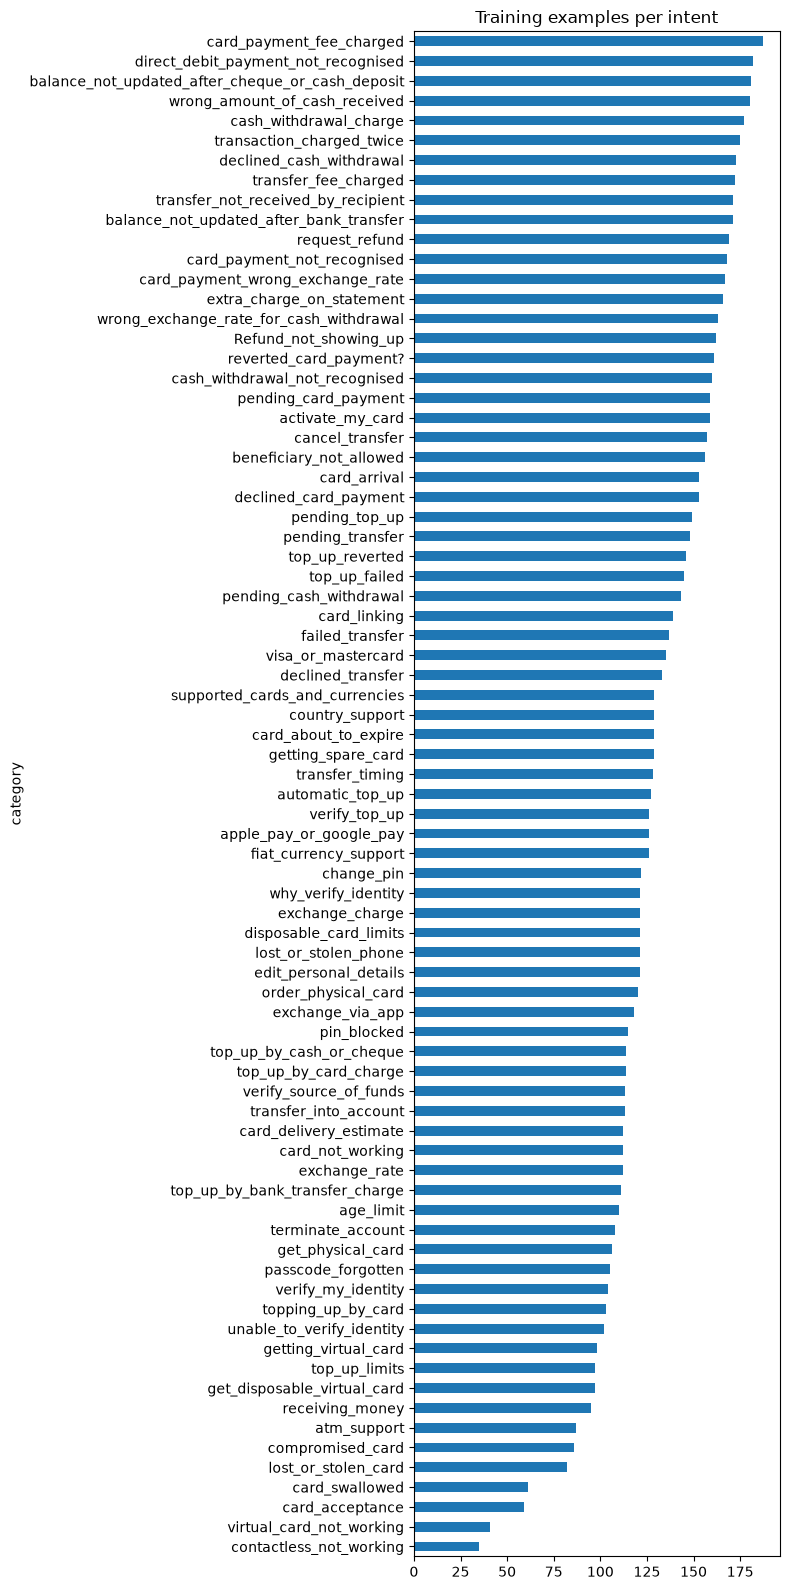

In [2]:
counts = train["category"].value_counts()
print("Number of intents:", counts.size)
print("Most examples:", counts.max(), " Fewest:", counts.min())

counts.sort_values().plot(kind="barh", figsize=(8, 16), title="Training examples per intent")
plt.tight_layout(); plt.show()


### Are the intents balanced?
- There are **77 intents**.
- The biggest intent (`card_payment_fee_charged`) has about **187** examples. The smallest (`contactless_not_working`) has about **35**.
- That's roughly a **5× difference**: some imbalance, but not extreme.
- **What this means for me:** accuracy alone could hide poor performance on small intents. So I'll also report **macro-F1**, which gives every intent equal weight.

count    10003.0
mean        11.9
std          7.9
min          2.0
25%          7.0
50%         10.0
75%         13.0
max         79.0
Name: n_words, dtype: float64


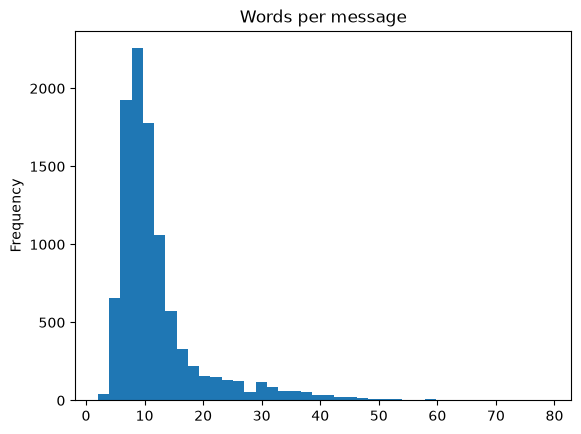

In [3]:
train["n_words"] = train["text"].str.split().str.len()
print(train["n_words"].describe().round(1))

train["n_words"].plot(kind="hist", bins=40, title="Words per message")
plt.show()

### How long are the messages?
- The typical message is **10 words** long. Half are between 7 and 13 words.
- A few are much longer (up to 79 words), but they're rare.
- **What this means for me:** most messages are one short sentence, so the model has only a few words to decide from. That makes similar intents hard to tell apart.

In [4]:
for intent in ["card_arrival", "card_delivery_estimate", "lost_or_stolen_card", "compromised_card"]:
    print(f"\n=== {intent} ===")
    for t in train[train["category"] == intent]["text"].head(3):
        print(" -", t)


=== card_arrival ===
 - I am still waiting on my card?
 - What can I do if my card still hasn't arrived after 2 weeks?
 - I have been waiting over a week. Is the card still coming?

=== card_delivery_estimate ===
 - Can it specifically be delivered on a certain date?
 - I need to get my card quickly
 - When can I expect my card? I live in the US.

=== lost_or_stolen_card ===
 - Has there been any activity on my card today?
 - I lost my wallet and all my cards were in it.
 - I'm panicking!  I lost my card!  Help!

=== compromised_card ===
 - I think someone is using my card without my permission!
 - What do I do if I detect fraudulent use on my car?
 - I think my account has been hacked there are charges on there I don't recognize.


### Some intents are almost identical
Messages for `card_arrival` ("Where is my card?") and `card_delivery_estimate` ("When will my card arrive?") use nearly the same words. The same goes for `lost_or_stolen_card` vs `compromised_card`.

**What this means for me:** even a good model will mix some of these up. A real support team doesn't need 77 separate queues anyway, so I'll also group the intents into a few **departments**. If the model confuses two card-delivery intents, the message still goes to the right team.